# dsdfit: a first example

This notebook walks through everything `dsdfit` does:

1. set up the physical conditions and the instrument's size bins;
2. look at what the two unknown parameters, $D_x$ and $\bar s$, do to the droplet size distribution;
3. make a synthetic histogram and fit it;
4. check that repeated fits recover the true values within their error bars;
5. read a histogram from a file (this is how you will bring in other data, such as C-ODT);
6. compare a fitted $D_x$ with the value predicted from supersaturation statistics, $a^2\sigma_s^2\tau$.

**Conventions.** Sizes you type are droplet *diameters* in micrometers (µm). $D_x$ is in µm⁴/s. The mean supersaturation $\bar s$ is a fraction: `0.0009` means 0.09%.

The guide (`docs/guide.pdf`) explains the physics and the method.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dsdfit import (Conditions, welas_bins, model_fractions, simulate, fit, plot_fit,
                    load_histogram, predicted_D_x)
from dsdfit.plots import log_diameter_axis   # log axis with plain labels: 1, 2, 5, 10, ...

## 1. Conditions and bins

`Conditions` holds the physical setting: temperature, pressure, the size of the dry salt particle each droplet forms on, and the chamber height. From these it computes the constants the model needs. Printing it shows them all.

In [2]:
cond = Conditions()        # defaults: T = 288 K, p = 1000 hPa, dry diameter 0.13 um, height 1 m
print(cond)

Conditions
  temperature  T     = 288 K
  pressure     p     = 100000 Pa
  dry diameter d_dry = 0.13 um
  chamber      H     = 1 m
Model constants
  growth       a     = 205.8 um^2/s
  curvature    A_k   = 0.001128 um
  solute       B_k   = 0.000365 um^3
  fallout      k     = 0.000121 1/(s um^2)
  critical supersaturation = 0.0007628 (0.0763%)


The WELAS instrument sorts droplets into size bins spaced evenly on a log scale. Droplets smaller than 1 µm in diameter are not counted reliably, so those bins are dropped.

In [3]:
edges = welas_bins(cutoff_diameter=1.0)
print(len(edges) - 1, "bins from", round(edges[0], 3), "to", edges[-1], "um")

103 bins from 1.023 to 40.0 um


## 2. What $D_x$ and $\bar s$ do

`model_fractions` gives the fraction of droplets the model expects in each bin. Change one parameter at a time and see how the distribution responds.

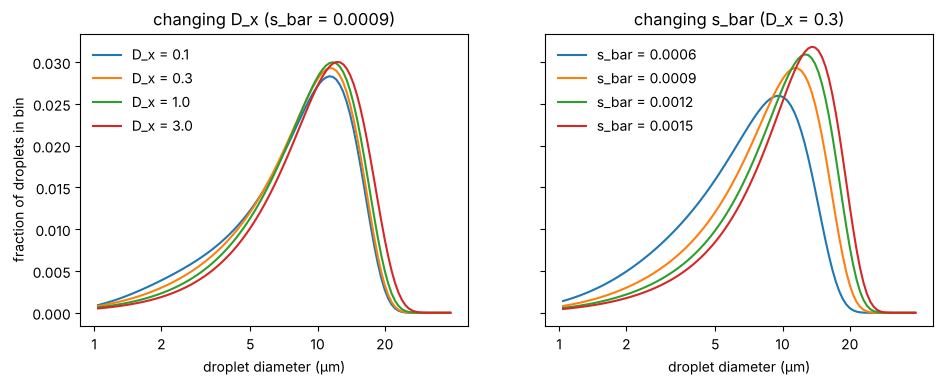

In [4]:
centers = np.sqrt(edges[:-1] * edges[1:])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)

for D_x in [0.1, 0.3, 1.0, 3.0]:
    axes[0].plot(centers, model_fractions(D_x, 0.0009, cond, edges), label=f"D_x = {D_x}")
axes[0].set_title("changing D_x (s_bar = 0.0009)")

for s_bar in [0.0006, 0.0009, 0.0012, 0.0015]:
    axes[1].plot(centers, model_fractions(0.3, s_bar, cond, edges), label=f"s_bar = {s_bar}")
axes[1].set_title("changing s_bar (D_x = 0.3)")

for ax in axes:
    log_diameter_axis(ax, edges[0], edges[-1])
    ax.set_xlabel("droplet diameter (µm)"); ax.legend(frameon=False)
axes[0].set_ylabel("fraction of droplets in bin")
plt.show()

Both parameters move droplets toward larger sizes. That makes them hard to tell apart, which is why their estimates end up correlated.

## 3. Simulate one histogram and fit it

`simulate` solves the model and then "counts" `n` droplets, each landing in a bin at random with the model's probabilities. The histogram remembers the true values, so we can check the fit.

In [5]:
hist = simulate(D_x=0.3, s_bar=0.0009, cond=cond, edges=edges, n=100_000, seed=1)
hist

Histogram(103 bins, 1.02-40 um diameter, n = 100000 droplets)

In [6]:
result = fit(hist, cond)
print(result)

D_x   = 0.278 +/- 0.02 um^4/s   (7.3%)
s_bar = 0.00090578 +/- 5.7e-06      (0.09058% +/- 0.00057 percentage points)
correlation between the two estimates: -0.84
fit check: J_min = 77.4, expected about 90 +/- 13 -> consistent with the model
(100000 droplets, 4 iterations)


The summary gives the two estimates with their error bars, the correlation between them, and a **fit check**: $J_{\min}$ measures how far the data are from the best-fitting model, and it should be close to its expected value if the model describes the data. A much larger $J_{\min}$ means the model does not fit.

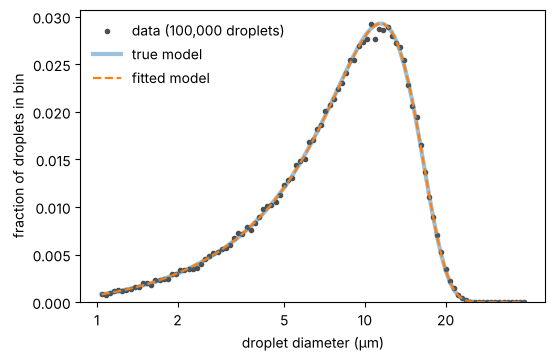

In [7]:
plot_fit(hist, result)
plt.show()

## 4. Do repeated fits recover the truth?

One fit can land a little high or low by chance. Repeat the experiment with 20 independent histograms and compare the estimates with the true values. An error bar of one standard deviation should contain the truth about 2 times in 3.

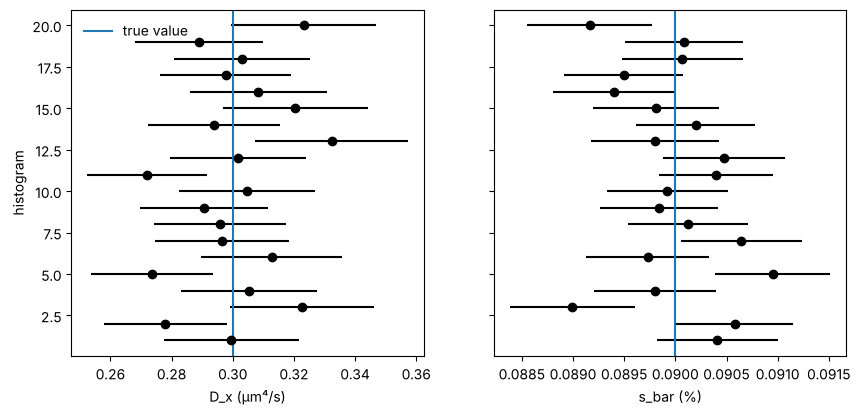

truth inside the error bar: 16 of 20 for D_x, 14 of 20 for s_bar


In [8]:
true_D, true_s = 0.3, 0.0009
results = [fit(simulate(true_D, true_s, cond, edges, n=100_000, seed=seed), cond) for seed in range(20)]

D   = np.array([r.D_x for r in results]);   D_err = np.array([r.D_x_err for r in results])
s   = np.array([r.s_bar for r in results]); s_err = np.array([r.s_bar_err for r in results])
row = np.arange(1, len(results) + 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
axes[0].errorbar(D, row, xerr=D_err, fmt="o", color="k")
axes[0].axvline(true_D, color="tab:blue", label="true value")
axes[0].set_xlabel("D_x (µm⁴/s)"); axes[0].set_ylabel("histogram"); axes[0].legend(frameon=False)
axes[1].errorbar(100 * s, row, xerr=100 * s_err, fmt="o", color="k")   # shown in percent
axes[1].axvline(100 * true_s, color="tab:blue")
axes[1].set_xlabel("s_bar (%)")
plt.show()

print("truth inside the error bar:",
      np.sum(np.abs(D - true_D) < D_err), "of 20 for D_x,",
      np.sum(np.abs(s - true_s) < s_err), "of 20 for s_bar")

## 5. Read a histogram from a file

Data from anywhere else (a simulation such as C-ODT, or an instrument) come in as a CSV file in the format described in the guide: one row per bin with the lower diameter, the upper diameter and the number of droplets. `data/example_histogram.csv` is a synthetic example made with `simulate`.

In [9]:
hist_file = load_histogram("../data/example_histogram.csv")
print(hist_file)
print(fit(hist_file, cond))

Histogram(103 bins, 1.02-40 um diameter, n = 100000 droplets)


D_x   = 0.2772 +/- 0.02 um^4/s   (7.3%)
s_bar = 0.00091002 +/- 5.7e-06      (0.091% +/- 0.00057 percentage points)
correlation between the two estimates: -0.84
fit check: J_min = 80.6, expected about 90 +/- 13 -> consistent with the model
(100000 droplets, 4 iterations)


For your own data, the only other thing to get right is `Conditions`: set the temperature, pressure, dry particle size and chamber height to the values of the run that produced the histogram.

## 6. Compare with the supersaturation statistics

The model's $D_x$ is related to how strongly, and for how long, the supersaturation fluctuates:

$$D_x \approx a^2 \sigma_s^2 \tau,$$

where $\sigma_s$ is the standard deviation of the supersaturation that droplets experience and $\tau$ is how long a fluctuation lasts. A simulation such as C-ODT can report both, so the fitted $D_x$ can be checked against them. Here the numbers are made up for illustration.

In [10]:
sigma_s, tau = 0.0019, 2.0        # made-up: supersaturation std (fraction) and time scale (s)
D_pred = predicted_D_x(sigma_s, tau, cond)
print(f"predicted D_x = {D_pred:.3f} um^4/s")
print(f"fitted    D_x = {result.D_x:.3f} +/- {result.D_x_err:.3f} um^4/s")
print(f"difference    = {(result.D_x - D_pred) / result.D_x_err:+.2f} error bars")

predicted D_x = 0.306 um^4/s
fitted    D_x = 0.278 +/- 0.020 um^4/s
difference    = -1.37 error bars


A difference of one or two error bars is normal; differences of many error bars would mean the two do not agree. In a real comparison, $\sigma_s$ and $\tau$ have uncertainties of their own, which should be taken into account too.

## Where to go next

The guide (`docs/guide.pdf`) describes the main task, fitting C-ODT histograms and comparing with $a^2\sigma_s^2\tau$, and a few warm-up questions to explore first, for example:

- How do the error bars change as the number of droplets `n` grows?
- What happens if `fit` assumes slightly wrong conditions (say, the wrong chamber height) compared with the ones used in `simulate`?
- Does the fit check notice?